In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df = pd.read_csv('/content/play_tennis.csv')

In [4]:
df

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [5]:
df.head()

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes


In [6]:
df.tail()

,day,outlook,temp,humidity,wind,play
9,D10,Rain,Mild,Normal,Weak,Yes
10,D11,Sunny,Mild,Normal,Strong,Yes
11,D12,Overcast,Mild,High,Strong,Yes
12,D13,Overcast,Hot,Normal,Weak,Yes
13,D14,Rain,Mild,High,Strong,No


In [7]:
df.describe()

,day,outlook,temp,humidity,wind,play
count,14,14,14,14,14,14
unique,14,3,3,2,2,2
top,D1,Sunny,Mild,High,Weak,Yes
freq,1,5,6,7,8,9


In [8]:
df.dtypes

,0
day,object
outlook,object
temp,object
humidity,object
wind,object
play,object


In [9]:
df.shape

(14, 6)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   day       14 non-null     object
 1   outlook   14 non-null     object
 2   temp      14 non-null     object
 3   humidity  14 non-null     object
 4   wind      14 non-null     object
 5   play      14 non-null     object
dtypes: object(6)
memory usage: 804.0+ bytes


In [23]:
#ENCODE CATEGORICAL -> NUMERIC

In [24]:
le = {} #create empty dictionary
df_enc = df.copy() #here we just cop our original data
for col in df.columns: #it convert into the text using loop through of the column
    le[col] = LabelEncoder() #now create new label for current data
    df_enc[col] = le[col].fit_transform(df[col])

In [25]:
df_enc

,day,outlook,temp,humidity,wind,play
0,0,2,1,0,1,0
1,6,2,1,0,0,0
2,7,0,1,0,1,1
3,8,1,2,0,1,1
4,9,1,0,1,1,1
5,10,1,0,1,0,0
6,11,0,0,1,0,1
7,12,2,2,0,1,0
8,13,2,0,1,1,1
9,1,1,2,1,1,1


In [26]:
#FEATURES & TARGET

In [28]:
x = df_enc[['outlook', 'temp', 'humidity', 'wind']]
y = df_enc['play']

In [29]:
x

,outlook,temp,humidity,wind
0,2,1,0,1
1,2,1,0,0
2,0,1,0,1
3,1,2,0,1
4,1,0,1,1
5,1,0,1,0
6,0,0,1,0
7,2,2,0,1
8,2,0,1,1
9,1,2,1,1


In [30]:
y

,play
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [32]:
from sklearn.naive_bayes import CategoricalNB

model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [37]:
test = [['Sunny', 'Cool', 'High', 'Strong']]

In [34]:
test

[['outlook', 'temp', 'humidity', 'wind']]

In [38]:
print("\n--Prediction-----")
for t in test:
  row_encoded = [
      le['outlook'].transform([t[0]])[0],
      le['temp'].transform([t[1]])[0],
      le['humidity'].transform([t[2]])[0],
      le['wind'].transform([t[3]])[0]
  ]
  row_df = pd.DataFrame([row_encoded], columns=['outlook', 'temp', 'humidity', 'wind'])
  pred = le['play'].inverse_transform(model.predict(row_df))[0]
  prob = model.predict_proba(row_df)[0]
  print(f"Input : outlook={t[0]}, temp={t[1]}, humidity={t[2]}, wind={t[3]}")
  print(f"Result : PlayTennis -> {pred}")
  print(f"P(No) = {prob[0]:.4f}")
  print(f"P(Yes) = {prob[1]:.4f}")


--Prediction-----
Input : outlook=Sunny, temp=Cool, humidity=High, wind=Strong
Result : PlayTennis -> No
P(No) = 0.7201
P(Yes) = 0.2799


In [39]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 92.86%


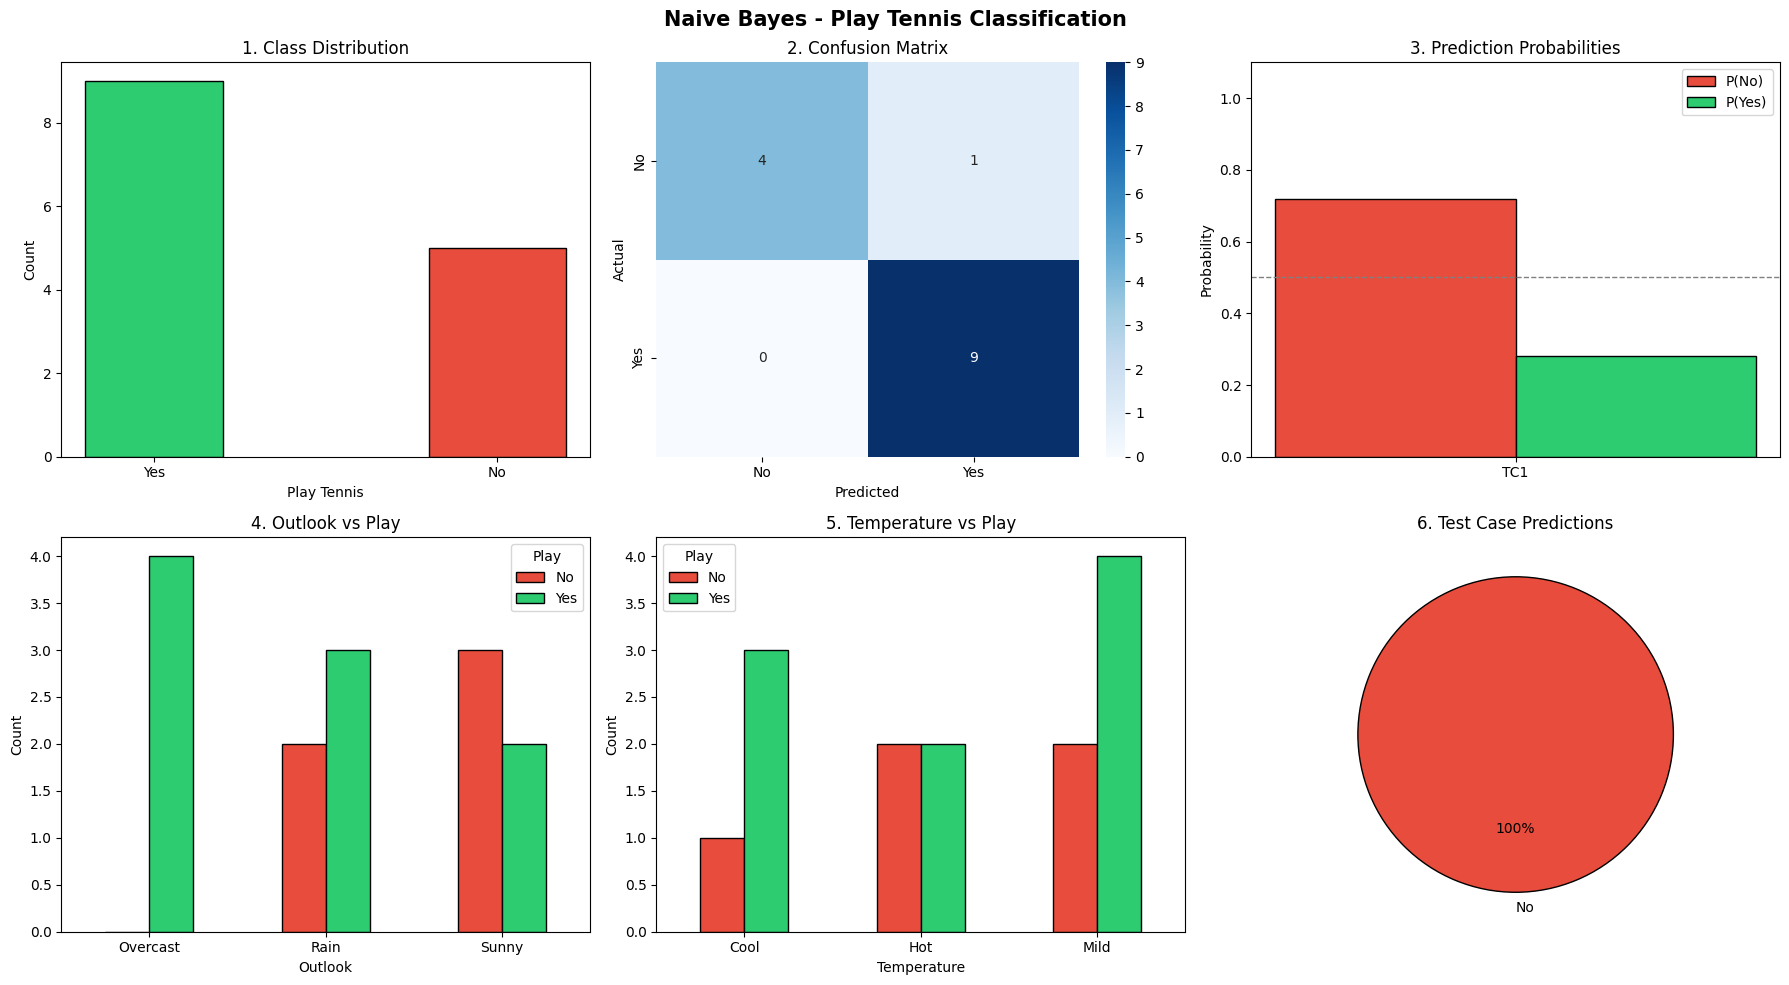

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

probs_no = []
probs_yes = []
predictions = []
for t in test:
    row_encoded = [
        le['outlook'].transform([t[0]])[0],
        le['temp'].transform([t[1]])[0],
        le['humidity'].transform([t[2]])[0],
        le['wind'].transform([t[3]])[0]
    ]
    row_df = pd.DataFrame([row_encoded], columns=['outlook', 'temp', 'humidity', 'wind'])
    prob = model.predict_proba(row_df)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])
    pred_class = le['play'].inverse_transform(model.predict(row_df))[0]
    predictions.append(pred_class)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Naive Bayes - Play Tennis Classification", fontsize=15, fontweight="bold")

# 1. Class Distribution
counts = df["play"].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c"], edgecolor="black", width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Play Tennis")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_coords = np.arange(len(tc_labels))
w = 0.35
axes[0, 2].bar(x_coords - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_coords + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_coords)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Outlook vs Play
outlook_counts = df.groupby(['outlook', 'play']).size().unstack(fill_value=0)
outlook_counts.plot(kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 0].set_title("4. Outlook vs Play")
axes[1, 0].set_xlabel("Outlook")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Play")

# 5. Temp vs Play
temp_counts = df.groupby(['temp', 'play']).size().unstack(fill_value=0)
temp_counts.plot(kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 1].set_title("5. Temperature vs Play")
axes[1, 1].set_xlabel("Temperature")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Play")

# 6. Test Case Predictions
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if label == 'Yes' else '#e74c3c' for label in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, autopct="%1.0f%%", colors=colors_pie, startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()